# 1. The geometry of least squares, with and without negative numbers

*Part 1 of a series on non-negative least squares (NNLS). Next:
[2. Optimality and enumeration](02_optimality_and_enumeration.ipynb).*

This series is about one small-looking problem:

$$\text{minimize } \|Rw - s\|^2 \quad \text{subject to } w \ge 0,$$

where $R$ is a matrix, $s$ a vector, and $w \ge 0$ means every entry of $w$ is non-negative.
Drop the "$w \ge 0$" and you have ordinary least squares, which you have probably met in a
linear algebra course. Keep it and the problem gets much more interesting. The tidy formula
$w = (R^\top R)^{-1}R^\top s$ stops working, and something more geometric takes its place.

This notebook is about that geometry. Here's the plan:

1. A real problem where the sign constraint matters.
2. Least squares as *projection onto a subspace*, proved with nothing but Pythagoras.
3. NNLS as *projection onto a cone*, and a test (the "obtuse-angle test") that tells you when
   you've found the closest point.
4. A map of the plane that shows exactly what NNLS does, and the idea it suggests for an
   algorithm.
5. Back to the real problem, now with pictures that explain it.

All you need is a first course in linear algebra: span, independence, dot products,
orthogonality. Each figure that has a slider is shown first as a few fixed snapshots, so the
notebook still reads if you're not running it. If you are, the widgets let you drag things
around.

In [1]:
%matplotlib inline
import numpy as np

from nnls_tutorial import plotting as P
from nnls_tutorial import widgets as W
from nnls_tutorial.data import load_arsenic
from nnls_tutorial.solvers import lstsq, nnls_enumerate, support_of

P.use_style()
np.set_printoptions(precision=4, suppress=True)

spectra = load_arsenic()
TEASER = ["Arsenopyrite_Julcani_OA", "As_pyrite_A_Foster_sln", "Lollingite_Lolling_avg_OA"]
BEST_FIT = [
    "Arsenopyrite_Julcani_OA",
    "orpiment_all_ref_als_cal",
    "arsenate_sorbed_diop_avg_als_cal",
]

## 1. A spectrum is a mixture

Shine X-rays at a sample containing arsenic and sweep the X-ray energy upward. Near
11,867 eV the arsenic atoms start absorbing strongly. The exact shape of that rise and its
wiggles depends on what the arsenic is bonded to. Chemists call this an X-ray absorption
near-edge structure (XANES) spectrum, and it works like a fingerprint. Arsenic in the mineral
arsenopyrite has one shape, arsenic in orpiment has another, and so on.

A real soil sample usually contains several arsenic compounds at once. Its spectrum is then
(to a very good approximation) a *weighted sum* of the spectra of those compounds, with each
weight giving the fraction of the arsenic in that form. So if we've measured a library of
*reference spectra* $r_1, \dots, r_m$ from pure compounds, we can ask how much of each one
best explains the measured spectrum $s$.

Each spectrum is a list of absorption values at the same $n$ energies, so each one is a
vector in $\mathbb{R}^n$. Put the references side by side as the columns of a matrix
$R = [r_1 \; r_2 \; \cdots \; r_m]$. A mixture with weights $w = (w_1, \dots, w_m)$ is then

$$Rw = w_1 r_1 + w_2 r_2 + \cdots + w_m r_m.$$

The measurement is noisy and the library is never perfect, so no weights will make $Rw$
equal $s$ exactly. Instead we make the *residual* (the error left over), $e = s - Rw$, as
small as possible in the usual length $\|e\| = \sqrt{e_1^2 + \cdots + e_n^2}$. That's least
squares.

Here's a real one: a measured spectrum from a soil sample, with three candidate references.

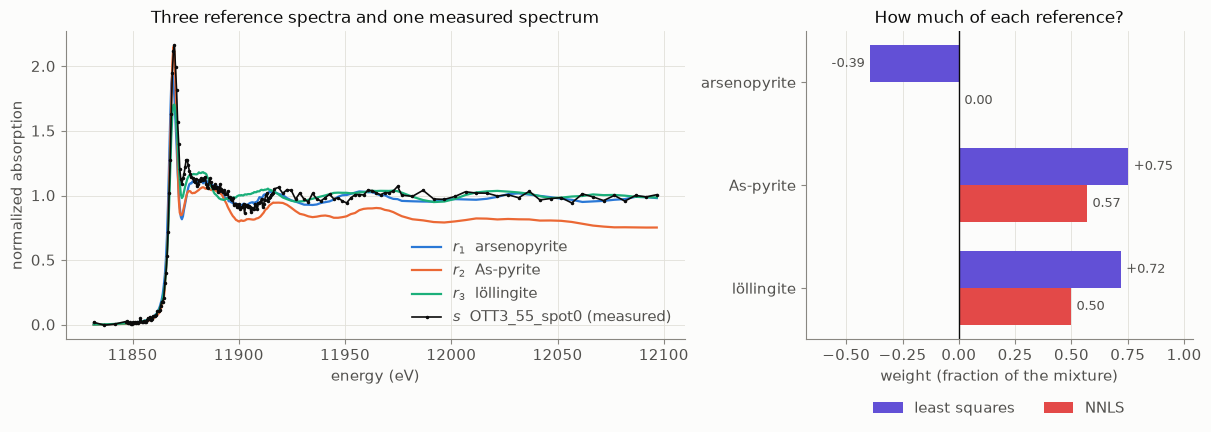

In [2]:
P.show(W.teaser_figure(spectra, TEASER))

**Figure 1.1.** Left: three reference spectra $r_1, r_2, r_3$ and the measured spectrum $s$
of sample OTT3_55, spot 0. Right: the weight least squares (purple) and NNLS (red) give
each reference.

Look at the purple bar in Figure 1.1. Ordinary least squares says the best mix is about 75% As-pyrite,
72% löllingite and **−39% arsenopyrite**.

That's not a small rounding issue. A negative amount of a mineral is physically meaningless.
The math is fine, though: least squares has found that *subtracting* a bit of the arsenopyrite
shape improves the fit, because it cancels some feature the other two over-predict. The
problem is that we asked the wrong question. What we actually want is

$$\boxed{\text{minimize } \|Rw - s\|^2 \text{ over all } w \text{ with every } w_i \ge 0.}$$

That's **non-negative least squares**, and its answer is the red bars: arsenopyrite switched
off completely, the other two adjusted to compensate. The fit is a little worse, since we
took options away, but now it means something.

How do you find that answer? Here's the catch. You can't solve least squares and then round
the negatives up to zero. Notice that the *other* weights changed too, from 0.75 and 0.72 to
0.57 and 0.50. To see why, and what to do instead, we need pictures.

### Shrinking the problem until we can draw it

The real problem lives in a big space:

In [3]:
print(
    f"{len(spectra.energies)} energies, so each spectrum is a vector in R^{len(spectra.energies)}"
)

198 energies, so each spectrum is a vector in R^198


Nobody can draw $\mathbb{R}^{198}$. Luckily, everything important about least squares
happens in tiny examples, with **two columns** in $\mathbb{R}^3$ or $\mathbb{R}^2$. We'll
work out the geometry there and then come back to the spectra, where (it turns out) the
pictures still apply.

## 2. Least squares is a projection

Forget the sign constraint for now. As $w$ ranges over all of $\mathbb{R}^m$, the vector $Rw$
ranges over the **column space** $\operatorname{col}(R) = \operatorname{span}(r_1, \dots, r_m)$.
So least squares asks for the point of a subspace closest to $s$.

In $\mathbb{R}^3$ with two independent columns, the column space is a plane through the
origin. Your intuition probably says the closest point is straight "below" $s$: drop a
perpendicular from $s$ to the plane and see where it lands. Call that point $p$
(Figure 1.2).

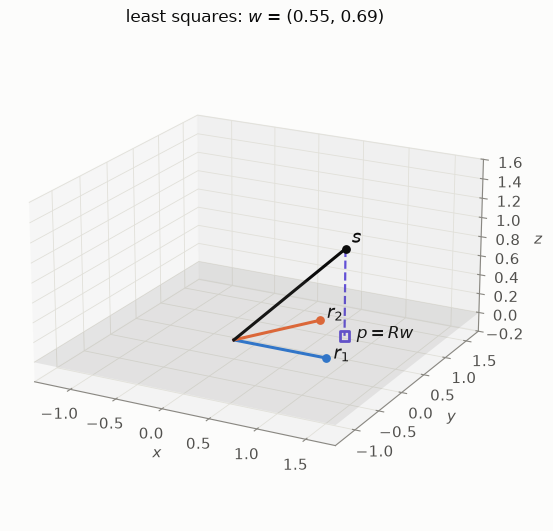

In [4]:
P.show(W.projection3d_figure(0.9, 0.6, 0.9, show_cone=False))

**Figure 1.2.** Least squares in $\mathbb{R}^3$. The gray plane is $\operatorname{col}(R)$,
spanned by $r_1$ and $r_2$. The point of the plane closest to $s$ is $p = R\hat w$, at the
foot of the perpendicular (dashed).

Your intuition is right, and the proof needs only Pythagoras.

> **Theorem 1 (least squares is orthogonal projection).** $\hat{w}$ minimizes
> $\|Rw - s\|$ if and only if the residual $\hat{e} = s - R\hat{w}$ is orthogonal to every
> column of $R$, that is,
> $$R^\top (s - R\hat{w}) = 0.$$

*Proof.* ($\Leftarrow$) Suppose $\hat e$ is orthogonal to every column. Take any $w$ and split
the residual it leaves:

$$s - Rw = \underbrace{(s - R\hat w)}_{\hat e} + \underbrace{R(\hat w - w)}_{\in\, \operatorname{col}(R)}.$$

The first piece is orthogonal to everything in $\operatorname{col}(R)$, including the second
piece. So by Pythagoras,

$$\|s - Rw\|^2 = \|\hat e\|^2 + \|R(\hat w - w)\|^2 \;\ge\; \|\hat e\|^2.$$

($\Rightarrow$) Suppose instead that $\hat e \cdot r_i \ne 0$ for some column $r_i$. Nudge the
$i$-th weight by $t$, which changes the residual to $\hat e - t r_i$, and expand:

$$\|\hat e - t r_i\|^2 = \|\hat e\|^2 - 2t\,(\hat e\cdot r_i) + t^2 \|r_i\|^2.$$

For small $t$ with the same sign as $\hat e \cdot r_i$, the middle term (size about $t$)
beats the last (size about $t^2$), so the total drops below $\|\hat e\|^2$. Then $\hat w$
wasn't the minimizer. $\blacksquare$

Keep an eye on that "nudge and expand" trick. It comes back in every proof in this notebook.

The equations $R^\top R \hat w = R^\top s$ are the **normal equations** ("normal" as in
perpendicular). When the columns of $R$ are independent, $R^\top R$ is invertible
(Exercise 1), so there's exactly one solution, $\hat w = (R^\top R)^{-1} R^\top s$.

Let's check Theorem 1 on the real spectra. If it's right, $R^\top \hat e$ should be zero, up
to rounding:

In [5]:
teaser_columns = [spectra.names.index(name) for name in TEASER]
R, s = spectra.R[:, teaser_columns], spectra.s
w_hat = lstsq(R, s)
e_hat = s - R @ w_hat
print("least-squares weights ŵ =", w_hat)
print("largest entry of R^T ê:", f"{np.abs(R.T @ e_hat).max():.1e}", " <- zero, up to rounding")

least-squares weights ŵ = [-0.3938  0.7517  0.7179]
largest entry of R^T ê: 8.2e-14  <- zero, up to rounding


## 3. Adding $w \ge 0$: projection onto a cone

Now put the constraint back. If every weight must be non-negative, $Rw$ can no longer reach
the whole column space, only the set

$$\operatorname{cone}(R) = \{Rw : w \ge 0\} = \{w_1 r_1 + \cdots + w_m r_m : \text{all } w_i \ge 0\}.$$

This is the **cone generated by the columns**. With two columns in a plane it's a wedge,
the region swept out between the rays through $r_1$ and $r_2$. With three columns in
$\mathbb{R}^3$ it's an infinite triangular pyramid with its tip at the origin. Two properties
matter:

- it's **convex**: the segment between any two of its points stays inside it (average two
  non-negative weight vectors and you get another one), and
- it's closed under **stretching**: if $c$ is in the cone, so is $tc$ for every $t \ge 0$.

NNLS asks for the point $q = Rw^*$ of the cone closest to $s$. Figure 1.3 shows the 3D
picture again with the wedge drawn in, for two positions of $s$. On the right of each is the
same plane seen from directly above.

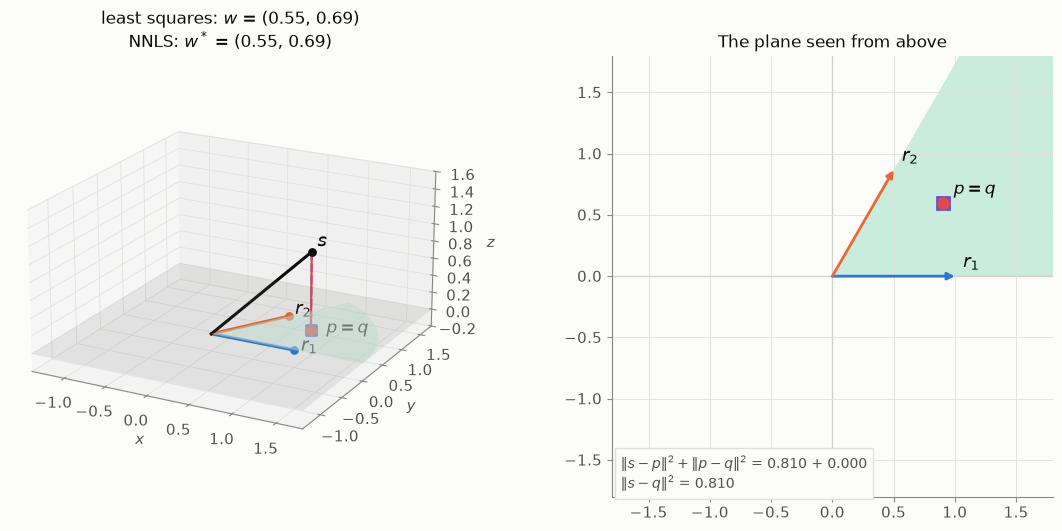

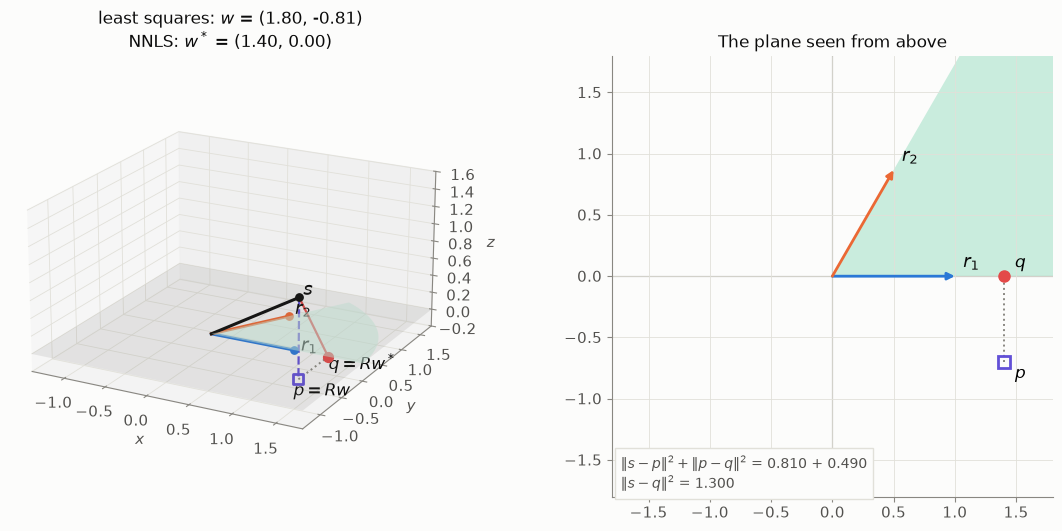

In [6]:
# Snapshots for reading without a kernel. Below them is a widget for moving s yourself.
W.projection3d_static()

**Figure 1.3.** Least squares and NNLS for two positions of $s$. In each row the left panel is
$\mathbb{R}^3$, with the cone (the wedge between $r_1$ and $r_2$) shaded in the plane, and the
right panel looks straight down on the plane. The hollow square $p$ is the projection onto
the plane, and the red dot $q$ is the projection onto the wedge. Top: $s$ is above the wedge,
so $q = p$. Bottom: $p$ falls outside the wedge, and $q$ lands on the ray through $r_1$. The
widget below draws the same figure for any $s$ and viewing angle.

In [7]:
W.projection3d_widget()

interactive(children=(FloatSlider(value=1.4, continuous_update=False, description='$s_1$', max=1.8, min=-1.4, …

In the top row of Figure 1.3, $s$ hovers over the wedge. Its shadow $p$ lands inside the wedge, so
the closest point of the wedge is $p$ itself, and NNLS agrees with least squares.

In the bottom row, the shadow $p$ lands *outside* the wedge. Least squares reports a negative
$w_2$, which is exactly what "outside the wedge, past $r_1$" means. NNLS has to settle for
the closest point $q$ on the edge of the wedge, the ray through $r_1$, with $w_2^* = 0$.

The box in each right-hand panel is checking something. In both rows,
$\|s - q\|^2 = \|s-p\|^2 + \|p-q\|^2$. That's no coincidence:

> **Theorem 2 (project first, then constrain).** Let $p$ be the least-squares projection of
> $s$ onto $\operatorname{col}(R)$. For every $c$ in $\operatorname{cone}(R)$,
> $$\|s - c\|^2 = \|s - p\|^2 + \|p - c\|^2.$$
> So the point of the cone closest to $s$ is the point of the cone closest to $p$.

*Proof.* $s - p$ is orthogonal to $\operatorname{col}(R)$ (Theorem 1), and $p - c$ lies in
$\operatorname{col}(R)$ because both $p$ and $c$ do. Pythagoras again. The first term doesn't
depend on $c$, so minimizing the left side is the same as minimizing the last term.
$\blacksquare$

That's a big deal for drawing. However large $n$ is, the NNLS problem effectively lives in
the $m$-dimensional column space. Three references? Then it's a 3D problem, even though the
spectra live in $\mathbb{R}^{198}$. We'll use this in Section 6.

## 4. How do you know you've found the closest point?

For a subspace, the test was "the residual is perpendicular to the subspace". A cone has
edges and a tip, so perpendicularity can't be the whole story. The bottom row of Figure 1.3
is a good example: $s - q$ is perpendicular to the $r_1$ ray but certainly not to $r_2$. The
right test is a little looser, as Figure 1.4 shows:

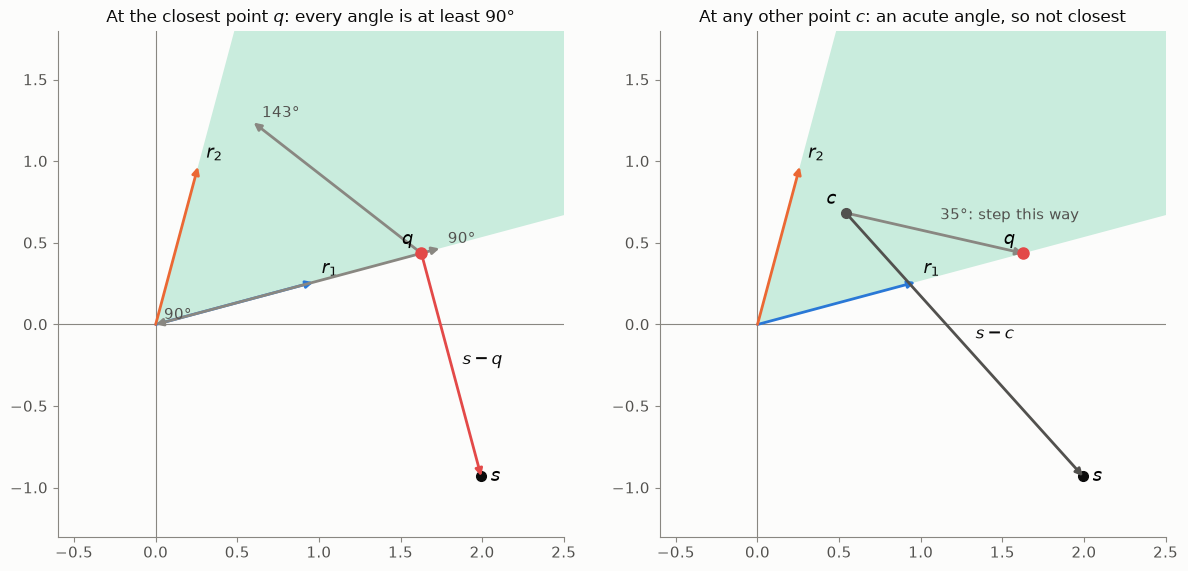

In [8]:
P.show(W.obtuse_angle_figure())

**Figure 1.4.** The obtuse-angle test. Left: standing at the closest point $q$, every point of
the cone (gray arrows) is at least $90°$ away from the direction $s - q$. Right: standing at a
point $c$ that isn't closest, the direction toward $q$ makes an acute angle with $s - c$.

> **Theorem 3 (the obtuse-angle test).** Let $C$ be a convex set and $q$ a point of $C$.
> Then $q$ is the point of $C$ closest to $s$ if and only if
> $$(s - q) \cdot (c - q) \le 0 \quad \text{for every } c \in C.$$
> In words: standing at $q$, every point of $C$ is at least $90°$ away from the direction of $s$.

*Proof.* ($\Leftarrow$) For any $c \in C$, write $s - c = (s - q) - (c - q)$ and expand:

$$\|s - c\|^2 = \|s-q\|^2 - 2\,(s-q)\cdot(c-q) + \|c-q\|^2 \;\ge\; \|s - q\|^2,$$

because the middle term is $\ge 0$ by assumption and the last is a square.

($\Rightarrow$) It's the nudge trick. Suppose some $c \in C$ has $(s-q)\cdot(c-q) > 0$. By
convexity the points $q + t(c - q)$ for $0 \le t \le 1$ are all in $C$, and

$$\|s - q - t(c-q)\|^2 = \|s-q\|^2 - 2t\,(s-q)\cdot(c-q) + t^2\|c-q\|^2,$$

which is less than $\|s - q\|^2$ for small $t > 0$. So $q$ wasn't closest. $\blacksquare$

The right panel of Figure 1.4 shows that second half in action. At a point $c$ of the cone
that isn't closest, some direction into the cone makes an acute angle with $s - c$, and
stepping that way gets you closer to $s$. (Notebook 3's algorithm is basically this idea,
carried out carefully.)

Two quick consequences. First, the answer is **unique**:

> **Theorem 4.** A convex set has at most one point closest to $s$.

*Proof.* If $q$ and $q'$ are both closest, the test at $q$ (with $c = q'$) and at $q'$ (with
$c = q$) gives

$$(s - q)\cdot(q' - q) \le 0 \quad\text{and}\quad (s - q')\cdot(q - q') \le 0.$$

Add them. The $s$'s cancel and you're left with $\|q - q'\|^2 \le 0$, so $q = q'$.
$\blacksquare$

Careful with what's unique here: the *point* $q = Rw^*$, not necessarily the *weights*
$w^*$. If two columns are identical, any split of weight between them gives the same $q$
(Exercise 3).

<details>
<summary><b>For the curious: why a closest point exists at all</b></summary>

For a subspace this was automatic: Theorem 1 produced the point. For a general convex set
it can fail. The open disk has no point closest to a point outside it, because you can
always creep closer to the missing boundary. What saves us is that $\operatorname{cone}(R)$
is **closed**. That's true, but less obvious than it looks. Here's an argument.

*Step 1 (Carathéodory for cones).* Every point of $\operatorname{cone}(R)$ is a non-negative
combination of a *linearly independent* subset of the columns. Take $c = Rw$ with $w \ge 0$
and the fewest possible non-zero weights. If the columns with $w_i > 0$ were dependent,
there'd be a $v \ne 0$, supported on those columns, with $Rv = 0$. Flipping its sign if
needed, some $v_i > 0$. Then $R(w - tv) = c$ for every $t$. Increase $t$ from 0 until the
first weight hits zero. That gives a representation with fewer non-zero weights, which is
a contradiction.

*Step 2.* If the columns of $R_P$ are independent, $\{R_P u : u \ge 0\}$ is closed. The
continuous function $u \mapsto \|R_P u\|$ is positive on the unit sphere, which is
compact, so it has a minimum $\sigma > 0$ there, and $\|R_P u\| \ge \sigma\|u\|$ for all $u$.
If $R_P u_k \to c$, the $u_k$ are therefore bounded, so a subsequence converges
(Bolzano–Weierstrass) to some $u \ge 0$, and $c = R_P u$.

*Step 3.* By step 1, $\operatorname{cone}(R)$ is the union of finitely many sets like the
ones in step 2, one for each independent subset of columns. A finite union of closed sets is
closed. Finally, minimizing the continuous function $\|s - c\|$ over the closed and bounded
set $\{c \in \operatorname{cone}(R): \|s - c\| \le \|s\|\}$, which isn't empty because it
contains $0$, gives a closest point.
</details>

### What the test says for a cone

Apply Theorem 3 to $C = \operatorname{cone}(R)$, with $q = Rw^*$ and residual $e = s - q$.
Three cheap choices of $c$ already say a lot:

- $c = 0$ and $c = 2q$ are both in the cone. They give $e \cdot (-q) \le 0$ and
  $e\cdot q \le 0$, so $e \cdot q = 0$.
- $c = q + r_i$ is in the cone (add 1 to the $i$-th weight). It gives $e \cdot r_i \le 0$
  for every column.

Now $0 = e \cdot q = \sum_i w_i^* \,(e\cdot r_i)$ is a sum of terms that are each $\le 0$
(non-negative weight times non-positive dot product), so every term is zero.

> **Theorem 5 (optimality conditions for NNLS).** $w^* \ge 0$ solves NNLS if and only if the
> residual $e = s - Rw^*$ satisfies, for every column $i$,
> - $e \cdot r_i \le 0$, and
> - $e \cdot r_i = 0$ whenever $w^*_i > 0$.

*Proof.* We just showed "only if". For "if", take any $c = Ru$ in the cone, with $u \ge 0$.
Then $e \cdot (c - q) = \sum_i u_i (e\cdot r_i) - \sum_i w^*_i (e \cdot r_i) \le 0 - 0$,
which is Theorem 3's test. $\blacksquare$

Compare this with Theorem 1. For the columns that are switched on ($w^*_i > 0$) the residual
is perpendicular, just as in least squares. For the columns that are switched off, it's
allowed to point away from them, but not towards them. (Notebook 2 derives these same
conditions from calculus, where they're called the KKT conditions, and puts them to work.)

Here they are on the real spectra:

In [9]:
w_star = nnls_enumerate(R, s)
e = s - R @ w_star
print("NNLS weights w* =", w_star)
print("R^T e         =", (R.T @ e).round(4) + 0.0)  # + 0.0 turns -0.0 into 0.0
print("switched on:", [spectra.labels[teaser_columns[i]] for i in support_of(w_star)])

NNLS weights w* = [0.     0.5685 0.4976]
R^T e         = [-0.2708  0.      0.    ]
switched on: ['As-pyrite', 'löllingite']


Arsenopyrite is switched off, and its dot product with the residual is negative, as
required. The other two are switched on, and their dot products are zero.

## 5. A map of the plane

Now let's go all the way down to two columns in $\mathbb{R}^2$, so that $s$ can be anywhere
in the plane, and color every possible $s$ by **which columns its NNLS answer switches on**.
Theorem 5 predicts four regions:

- **both on**: $e$ is perpendicular to both columns, so $e = 0$. That means $s$ is inside the
  cone.
- **only $r_1$ on**: $e \perp r_1$ and $e \cdot r_2 \le 0$. Here $s$ drops perpendicularly
  onto the $r_1$ ray.
- **only $r_2$ on**: the same with the roles swapped.
- **$w^* = 0$**: $e = s$ and $s\cdot r_1 \le 0$, $s \cdot r_2 \le 0$. Here $s$ points away
  from both columns, and the best you can do is the origin.

Figure 1.5 shows exactly these four regions.

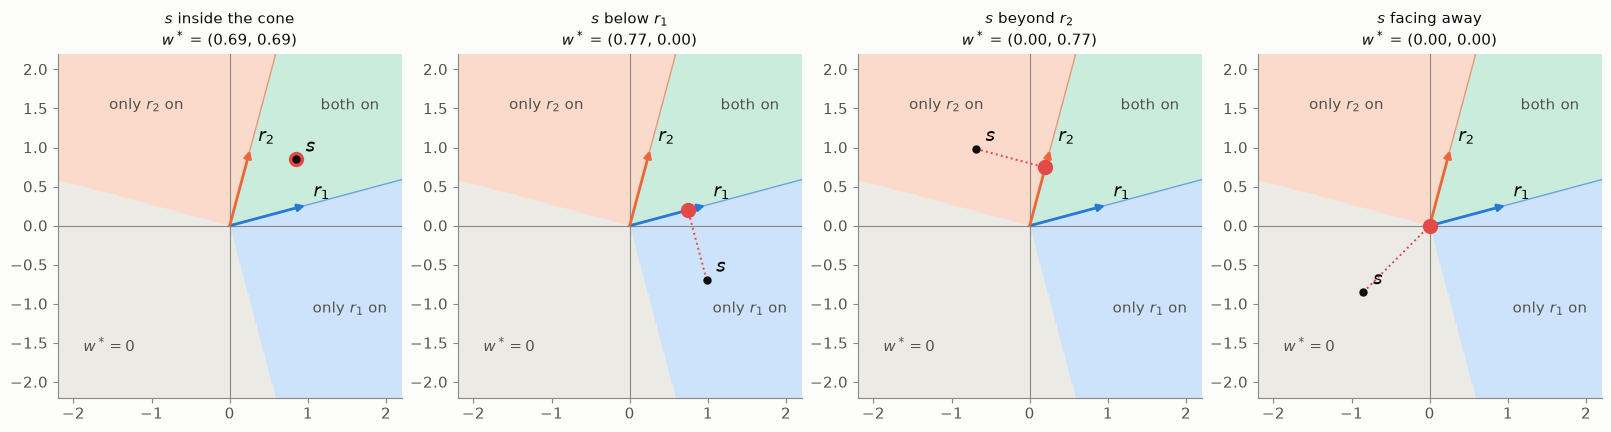

In [10]:
W.regions_static()

**Figure 1.5.** Every point of the plane, colored by which columns its NNLS fit switches on,
for two columns $60°$ apart. In each panel $s$ is the black dot and the red dot is its NNLS
projection $q = Rw^*$. The four panels put $s$ in each of the four regions in turn. The widget
below lets you move $s$ and change the angle between the columns.

In [11]:
W.regions_widget()

interactive(children=(IntSlider(value=60, continuous_update=False, description='angle between $r_1$ and $r_2$ …

Use the widget to play with the angle between the columns. The four regions always tile the plane, and their
boundaries are always perpendicular to a column ray or along one. (Can you predict how the
gray region changes when the angle passes $90°$? That's Exercise 2.)

Now the observation the rest of this series is built on. **Inside each region, the NNLS
answer is an ordinary least-squares fit**: least squares using only the switched-on
columns, with zeros for the rest. In the "only $r_1$" region, $w_1^*$ is just the
least-squares weight for fitting $s$ by $r_1$ alone. The constraint never changes the
answer *within* a region. It only decides *which region* you're in.

This is true in general. By Theorem 5, the residual is perpendicular to the switched-on
columns, and by Theorem 1 that makes $w^*$ (restricted to those columns) their
least-squares fit. So here's an algorithm. If there are only a few columns, try every subset
of them, fit each by least squares, throw away fits with a negative weight, and keep the
best of what's left. With $m$ columns that's $2^m - 1$ subsets: 3 for two columns, 31 for
five. Notebook 2 proves this always gives the right answer. The fast solver in notebook 5 is
exactly this idea, carried out very efficiently.

On the real spectra, refitting just the switched-on columns by least squares gives back the
NNLS weights:

In [12]:
on = list(support_of(w_star))
print("NNLS weights on the switched-on columns:", w_star[on])
print("least squares using only those columns: ", lstsq(R[:, on], s))

NNLS weights on the switched-on columns: [0.5685 0.4976]
least squares using only those columns:  [0.5685 0.4976]


## 6. Back to the spectra: the triangle of mixtures

Theorem 2 says the real three-reference problem is really a 3D problem: project $s$ onto the
column space, then find the nearest point of the cone. A 3D cone is hard to read on a
screen, but the spectra hand us a better view.

These spectra are *normalized* (each one's jump at the edge is scaled to 1), so the weights of
a sensible mixture add up to about 1. Divide any weight vector by its sum and you get
**mixture coordinates**, three numbers that add up to exactly 1. Points with mixture
coordinates fill a triangle whose corners are the three pure references. These are exactly
the barycentric coordinates you may have seen in geometry. Non-negative weights put the
point inside the triangle or on its edge. A negative weight pushes it out past the opposite
edge.

Figure 1.6 shows our example, and below it MrFitty's actual best answer for this sample,
which uses a different trio of references.

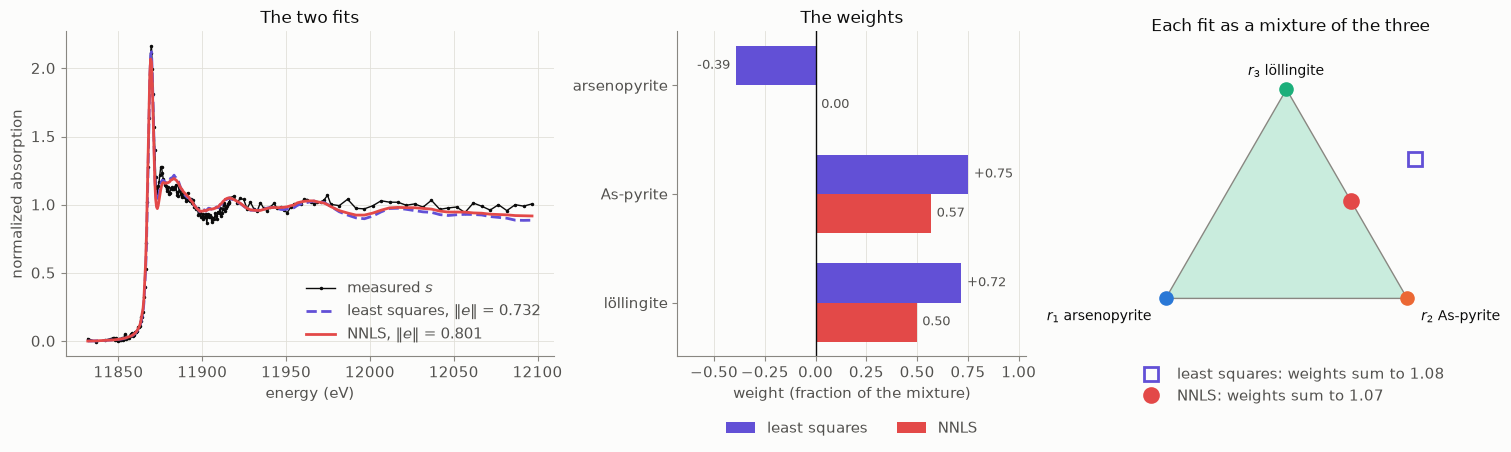

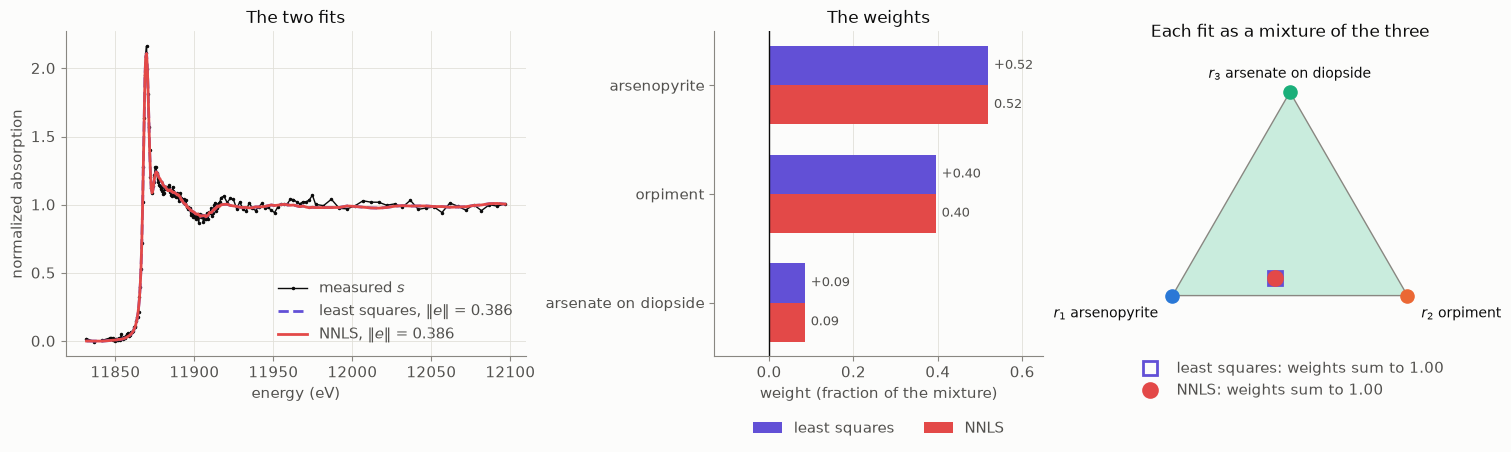

In [13]:
W.mixtures_static(spectra, [TEASER, BEST_FIT])

**Figure 1.6.** Two three-reference fits of the measured spectrum. Left: the least-squares
and NNLS fits, with the size $\|e\|$ of each residual. Middle: the weights. Right: each fit as
a mixture. The corners are the pure references, and a point's position is given by its weights
divided by their sum. Top: the trio from Figure 1.1, where least squares lands outside the
triangle. Bottom: MrFitty's reported best fit for this sample, where it lands inside. The
widget below draws the same figure for any three of the ten bundled references.

In the top row of Figure 1.6, the least-squares square sits *outside* the triangle, beyond the edge
opposite arsenopyrite. That's the −0.39. NNLS lands *on* that edge, with arsenopyrite at
zero. This is the four-region picture of Figure 1.5 again, one dimension up: an edge of the triangle is a
face of the cone, and the face it lands on is the subset of references switched on.

In the bottom row, least squares lands inside the triangle by itself, so NNLS has nothing to
fix and the two answers coincide. The weights (0.52, 0.40, 0.09) match MrFitty's summary for
this sample.

Try other trios. The widget lets you pick any three of the ten bundled references:

In [14]:
W.mixtures_widget(spectra)

interactive(children=(Dropdown(description='$r_1$', options=(('arsenopyrite', 'Arsenopyrite_Julcani_OA'), ('As…

One trio to try: **As$_2$O$_3$** with **sodium arsenite** and anything else. Those two
references are almost the same spectrum, and least squares responds with huge weights of
opposite sign (around $+7.7$ and $-7.4$ with arsenopyrite as the third), cancelling each
other to fit the noise. That's a sign of an *ill-conditioned* problem. Notebook 4 is about
why that happens and what it does to the numerics.

## Exercises

**1.** Prove that $R^\top R$ is invertible if and only if the columns of $R$ are linearly
independent. *(Hint: look at $w^\top R^\top R w$.)*

<details><summary>Solution</summary>

If the columns are dependent, there's $w \ne 0$ with $Rw = 0$, so $R^\top R w = 0$ and
$R^\top R$ is singular. Conversely, if $R^\top R w = 0$ then
$0 = w^\top R^\top R w = (Rw)\cdot(Rw) = \|Rw\|^2$, so $Rw = 0$, and independence forces
$w = 0$. So the only solution of $R^\top R w = 0$ is $w = 0$, which means $R^\top R$ is
invertible.
</details>

**2.** In the plane, with two columns at angle $\theta$, show that the region where
$w^* = 0$ is exactly $\{s : s\cdot r_1 \le 0 \text{ and } s\cdot r_2 \le 0\}$. What's the
angle of that wedge? Predict what happens to the gray region as $\theta$ grows past $90°$,
then check with the widget under Figure 1.5.

<details><summary>Solution</summary>

By Theorem 5 with $w^* = 0$, the residual is $e = s$, and the conditions are $s\cdot r_i \le 0$
for both $i$ (the "switched on" condition is empty). Conversely, if both dot products are
$\le 0$ then $w^* = 0$ passes Theorem 5's test.

The set $\{s : s\cdot r_1 \le 0\}$ is a half-plane whose edge is perpendicular to $r_1$.
Rotating from $r_1$'s half-plane boundary to $r_2$'s turns through $\theta$, so the
intersection of the two half-planes is a wedge of angle $180° - \theta$. It shrinks as the
columns open up. At $\theta = 90°$ it's a quarter-plane, and as $\theta \to 180°$ it
collapses to a ray. That makes sense: a wider cone leaves fewer directions that point away
from all of it.
</details>

**3.** Find a $2 \times 2$ matrix $R$ and a vector $s$ for which the closest point $q$ of
the cone is unique (as Theorem 4 promises) but the NNLS weights $w^*$ are not. Which step of
the "try every subset" idea from Section 5 has to cope with this?

<details><summary>Solution</summary>

Take $r_1 = (1, 0)$, $r_2 = (2, 0)$ and $s = (1, 1)$. The cone is the ray along the positive
horizontal axis, and the closest point is $q = (1, 0)$. Every $w^* = (t, (1-t)/2)$ with
$0 \le t \le 1$ gives it. In the subset method, the subset $\{r_1, r_2\}$ has dependent
columns, so its least-squares fit isn't unique ($R^\top R$ is singular, by Exercise 1). The
method has to skip such subsets or handle them specially. Notebook 2 shows that skipping
them is safe. That's what Step 1 in the "for the curious" box is really saying.
</details>

**4.** Suppose the columns of $R$ are independent and $s$ is in $\operatorname{cone}(R)$.
Show that least squares and NNLS give the same weights.

<details><summary>Solution</summary>

Write $s = Ru$ with $u \ge 0$. Then $\|Ru - s\| = 0$, so $u$ minimizes $\|Rw - s\|$ over
*all* $w$. By Theorem 1 and Exercise 1 the least-squares minimizer is unique, so
$\hat w = u$. And $u$ is feasible for NNLS with error $0$, which can't be beaten, so
$w^* = u$ too (unique by Theorem 4 plus independence: $Rw^* = q = Ru$ forces $w^* = u$).
</details>

## Summary

- Least squares finds the point of the **subspace** $\operatorname{col}(R)$ closest to $s$.
  The residual is perpendicular to every column (Theorem 1).
- NNLS finds the point of the **cone** $\{Rw : w \ge 0\}$ closest to $s$. That point is unique
  (Theorem 4), and you can find it by projecting onto the subspace first (Theorem 2).
- The test for "closest" is the obtuse-angle test (Theorem 3). For a cone it becomes the
  optimality conditions of Theorem 5: perpendicular to the columns that are switched on, and
  pointing away from the ones that are switched off.
- The cone carves space into regions, one for each subset of columns that can be switched
  on. Within a region, NNLS is plain least squares on that subset.

**Next:** [notebook 2](02_optimality_and_enumeration.ipynb) turns that last observation into
an algorithm and proves that it's exact, using a calculus-based view of the same conditions.